# Workshop 2: Data Profiling & Quality Risk Analysis
**Faculty of Engineering and Basic Sciences**  
**Academic Program:** Data Engineering and Artificial Intelligence  
**Course:** ETL (G01)  
**Scenario:** Spotify Catalog & Grammy Awards Integration  

---
### Objectives of this Notebook:
1. Conduct empirical, evidence-based profiling of both source datasets (`spotify_dataset.csv` and `the_grammy_awards.csv`).
2. Evaluate 7 profiling dimensions: **Structure, Completeness, Uniqueness, Categorical Content, Numerical Content, Temporal Content, and Cross-Source Consistency**.
3. Identify concrete quality risks that threaten downstream analytical requirements (**REQ-01, REQ-02, REQ-03**).
4. Define explicit metrics, thresholds, and severity levels to govern automated validation gates in **Great Expectations**.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 10})


## 1. Data Acquisition & Structural Profiling
We load both datasets from source storage and inspect schema, data types, and primary grain.


In [2]:
import os
from pathlib import Path

# Resolve data path robustly whether run from project root or notebooks/ directory
if os.path.exists("spotify_dataset.csv"):
    base_data_path = Path(".")
elif os.path.exists("../spotify_dataset.csv"):
    base_data_path = Path("..")
else:
    base_data_path = Path(".").resolve()

df_spotify = pd.read_csv(base_data_path / "spotify_dataset.csv")
df_grammy = pd.read_csv(base_data_path / "the_grammy_awards.csv")

print(f"Spotify shape: {df_spotify.shape[0]:,} rows x {df_spotify.shape[1]} columns")
print(f"Grammy shape:  {df_grammy.shape[0]:,} rows x {df_grammy.shape[1]} columns")


Spotify shape: 114,000 rows x 21 columns
Grammy shape:  4,810 rows x 10 columns


In [3]:
# Inspect schemas and sample records
display(df_spotify.head(3))
display(df_grammy.head(3))


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,...,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,...,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,...,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic


,year,title,published_at,updated_at,category,nominee,artist,workers,img,winner
0,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,Bad Guy,Billie Eilish,"Finneas O'Connell, producer; Rob Kinelski & Fi...",https://www.grammy.com/sites/com/files/styles/...,True
1,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,"Hey, Ma",Bon Iver,"BJ Burton, Brad Cook, Chris Messina & Justin V...",https://www.grammy.com/sites/com/files/styles/...,True
2,2019,62nd Annual GRAMMY Awards (2019),2020-05-19T05:10:28-07:00,2020-05-19T05:10:28-07:00,Record Of The Year,7 rings,Ariana Grande,"Charles Anderson, Tommy Brown, Michael Foster ...",https://www.grammy.com/sites/com/files/styles/...,True


## 2. Completeness & Missing Value Analysis
Missing data can silently corrupt aggregations and foreign key joins.


In [4]:
spot_nulls = df_spotify.isnull().sum()
gram_nulls = df_grammy.isnull().sum()

print("--- Spotify Missing Values ---")
print(spot_nulls[spot_nulls > 0])

print("\n--- Grammy Missing Values ---")
print(gram_nulls[gram_nulls > 0])


--- Spotify Missing Values ---
artists       1
album_name    1
track_name    1
dtype: int64

--- Grammy Missing Values ---
nominee       6
artist     1840
workers    2190
img        1367
dtype: int64


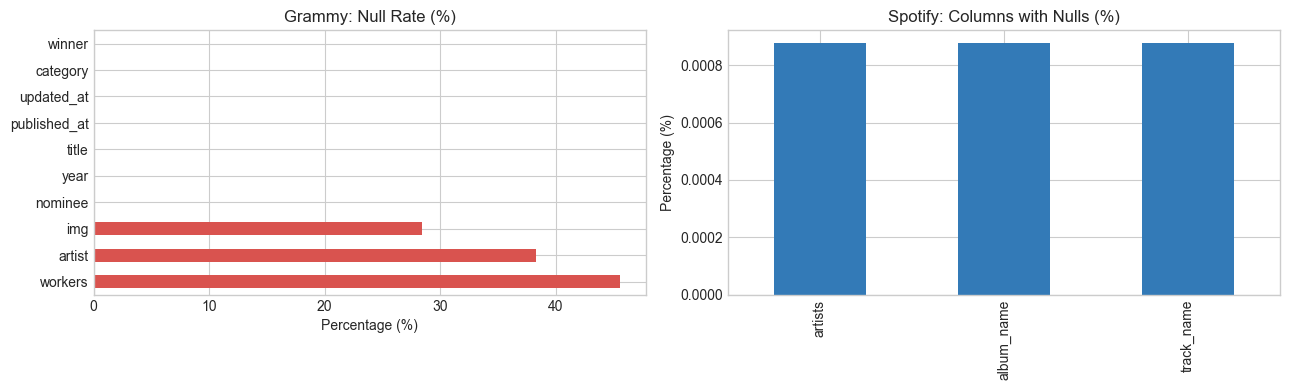

In [5]:
# Visualize Missing Values
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

(gram_nulls / len(df_grammy) * 100).sort_values(ascending=False).plot(
    kind='barh', ax=axes[0], color='#D9534F', title='Grammy: Null Rate (%)'
)
axes[0].set_xlabel('Percentage (%)')

(spot_nulls[spot_nulls > 0] / len(df_spotify) * 100).plot(
    kind='bar', ax=axes[1], color='#337AB7', title='Spotify: Columns with Nulls (%)'
)
axes[1].set_ylabel('Percentage (%)')
plt.tight_layout()
plt.show()


## 3. Uniqueness and Duplication Analysis
Evaluating candidate keys and duplicate behaviors.


In [6]:
total_tracks = len(df_spotify)
unique_tracks = df_spotify['track_id'].nunique()
duplicate_track_rows = total_tracks - unique_tracks

print(f"Total Spotify records:        {total_tracks:,}")
print(f"Unique track_id occurrences:  {unique_tracks:,}")
print(f"Multi-genre duplicate rows:   {duplicate_track_rows:,} ({duplicate_track_rows/total_tracks*100:.1f}%)")

# Inspect reasons for duplicates: Tracks assigned to multiple genre tags
sample_dups = df_spotify[df_spotify.duplicated(subset=['track_id'], keep=False)].sort_values('track_id')
sample_dups[['track_id', 'track_name', 'artists', 'track_genre']].head(6)


Total Spotify records:        114,000
Unique track_id occurrences:  89,741
Multi-genre duplicate rows:   24,259 (21.3%)


,track_id,track_name,artists,track_genre
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,chill
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,soul
85578,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,punk-rock
100420,001YQlnDSduXd5LgBd66gT,El Tiempo Es Dinero - Remasterizado 2007,Soda Stereo,ska
91801,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,rock
3257,003vvx7Niy0yvhvHt4a68B,Mr. Brightside,The Killers,alternative


## 4. Numerical Content & Boundary Verification
Audio characteristics must adhere to strictly defined mathematical and physics domains:
- Audio features (`danceability`, `energy`, `valence`, `acousticness`): $[0.0, 1.0]$
- Popularity: $[0, 100]$


In [7]:
num_cols = ['popularity', 'duration_ms', 'danceability', 'energy', 'valence', 'tempo']
df_spotify[num_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.0,17.00000,35.000,50.000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.0,174066.00000,212906.000,261506.000,5237295.000
danceability,114000.0,0.566800,0.173542,0.0,0.45600,0.580,0.695,0.985
energy,114000.0,0.641383,0.251529,0.0,0.47200,0.685,0.854,1.000
valence,114000.0,0.474068,0.259261,0.0,0.26000,0.464,0.683,0.995
tempo,114000.0,122.147837,29.978197,0.0,99.21875,122.017,140.071,243.372


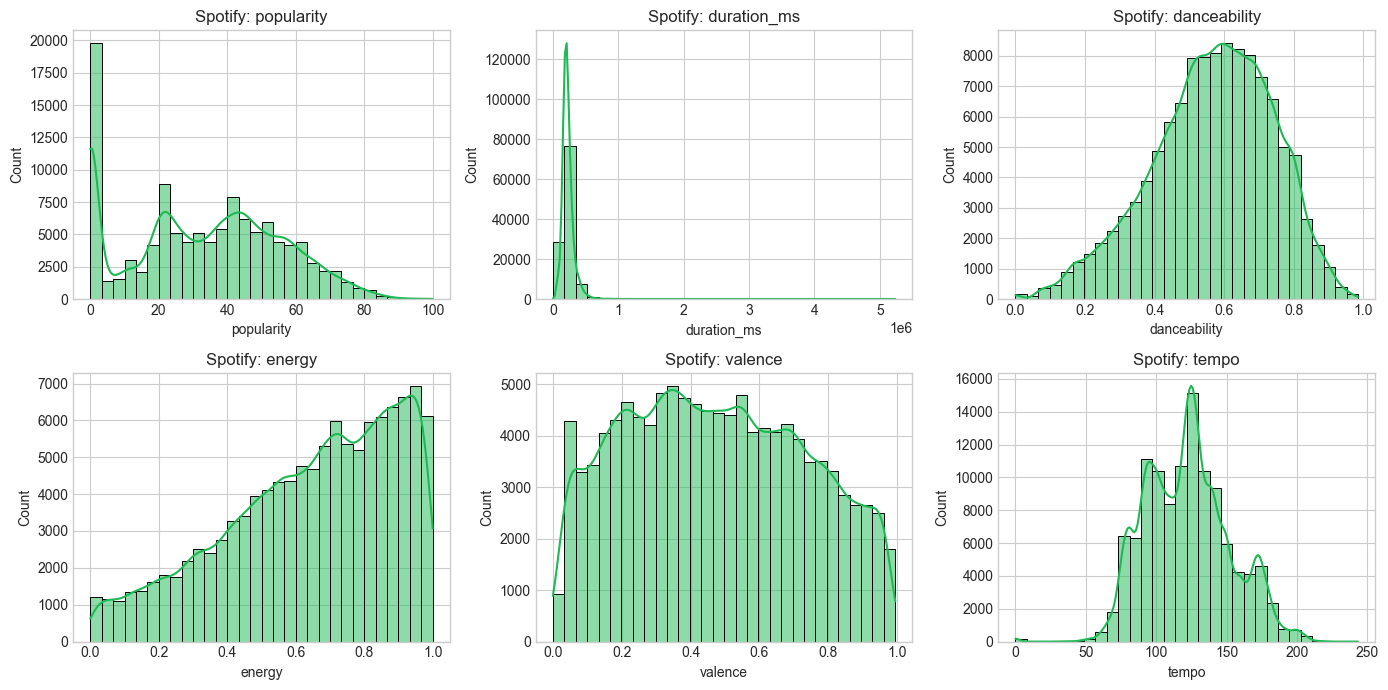

In [8]:
# Plot Numerical Feature Distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df_spotify[col], bins=30, kde=True, ax=axes[i], color='#1DB954')
    axes[i].set_title(f'Spotify: {col}')

plt.tight_layout()
plt.show()


## 5. Temporal Content & Award Coverage
The Grammy dataset covers 1958 to 2019 without temporal gaps.


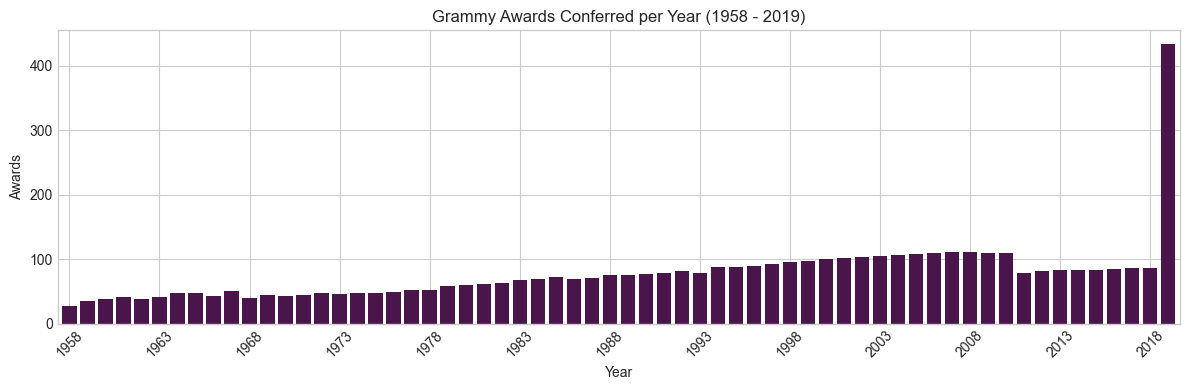

In [9]:
year_counts = df_grammy['year'].value_counts().sort_index()

plt.figure(figsize=(12, 4))
year_counts.plot(kind='bar', color='#4A154B', width=0.8)
plt.title('Grammy Awards Conferred per Year (1958 - 2019)')
plt.xticks(range(0, len(year_counts), 5), year_counts.index[::5], rotation=45)
plt.xlabel('Year')
plt.ylabel('Awards')
plt.tight_layout()
plt.show()


## 6. Cross-Source Consistency & Entity Harmonization
Analyzing entity resolution between Spotify artists and Grammy award recipients.
Multi-artist collaborations in Spotify use semicolons (`;`), while Grammy awards use `&`, `Featuring`, or `With`.


In [10]:
# Tokenize Spotify artists
spotify_artists = set()
for a in df_spotify['artists'].dropna().unique():
    for sub in str(a).split(';'):
        spotify_artists.add(sub.strip().lower())

grammy_artists = set(df_grammy['artist'].dropna().str.lower().str.strip().unique())
matched_artists = spotify_artists.intersection(grammy_artists)

print(f"Tokenized unique Spotify artists: {len(spotify_artists):,}")
print(f"Unique Grammy artists:           {len(grammy_artists):,}")
print(f"Direct artist match count:        {len(matched_artists):,} ({len(matched_artists)/len(grammy_artists)*100:.1f}% match rate)")


Tokenized unique Spotify artists: 29,811
Unique Grammy artists:           1,656
Direct artist match count:        524 (31.6% match rate)


## 7. Quality Risk Register & Synthesis
The table below connects profiling findings directly to analytical requirements and Great Expectations rules:

| Dataset / Attribute | Profiling Evidence | Potential Quality Risk | Related Requirement | Severity | Engineering Action |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `spotify.track_id` | 89,741 unique IDs across 114,000 rows | Multi-genre tracks cause duplicate key violations if grain is track_id alone | REQ-01, REQ-02 | Critical | Declare composite grain `(track_id, genre)` in fact table; deduplicate in `dim_track`. |
| `spotify.audio_features` | 100% of danceability, energy, valence are in $[0, 1]$ | Out-of-bounds or negative values would invalidate audio signature analytics | REQ-01, REQ-03 | Critical | GX rule: `expect_column_values_to_be_between(0.0, 1.0)`. |
| `spotify.artists` | 1 null record; multiple artists joined by `;` | Semicolons prevent direct join with single artist strings | REQ-01, REQ-02 | Warning | Clean nulls; tokenize multi-artist collaborations into individual artist entities. |
| `grammy.year` | Values span 1958 to 2019; no nulls | Future or negative years would invalidate temporal era analysis | REQ-03 | Critical | GX rule: `expect_column_values_to_be_between(1958, 2026)`. |
| `grammy.artist` | 1,840 nulls (38.3%) | Missing artist column would cause missed matches in song-writing awards | REQ-01, REQ-02 | Warning | Harmonization logic: extract performer/songwriter from `workers` and `nominee` when `artist` is null. |
| `grammy.category` | 4,810 non-null values | Null category prevents award taxonomy classification | REQ-03 | Critical | GX rule: `expect_column_values_to_not_be_null`. |
